# Event Detection and Voice Activity Detection on the VOiCES Dataset

**Name:** Ali hussien alrekabi &nbsp;&nbsp;&nbsp;&nbsp; **ID:** 404131078

---

## 1. Introduction
In this assignment, I used the VOiCES dataset to perform two tasks. The first task is acoustic event detection, where the goal is to identify the type of background noise in a recording. The second task is voice activity detection (VAD), where the goal is to decide for every short frame of audio whether it contains speech or not. VOiCES is a challenging dataset because the speech was recorded in real rooms with reverberation and background noise played at the same time.

# Part 1: Acoustic Event Detection (noise type classification)

## 2. Dataset
I used the subset of VOiCES provided by Lab41 on GitHub, where the main speaker is placed at 90 degrees. The audio files were stored in eight tar archives, which I extracted in Google Colab. The subset contains 908 audio recordings. Each recording is about 15 to 16 seconds long, with a sampling rate of 16000 Hz. The recordings come from 104 different speakers in two rooms.

In [1]:
!git clone https://github.com/Lab41/VOiCES-subset.git
!du -sh VOiCES-subset
!ls VOiCES-subset

fatal: destination path 'VOiCES-subset' already exists and is not an empty directory.
734M	VOiCES-subset
'Feature Extraction.ipynb'			      VOiCES_90_4.tar
 Lab41-SRI-VOiCES_ref_SUBSET.csv		      VOiCES_90_5.tar
 Lab41-SRI-VOiCES-speaker-gender-dataset_SUBSET.csv   VOiCES_90_6.tar
'Loading VOiCES data.ipynb'			      VOiCES_90_7.tar
 README.md					      VOiCES_90_8.tar
 VOiCES_90_1.tar				      VOiCES_90deg_features.csv
 VOiCES_90_2.tar				      VOiCES_workshop
 VOiCES_90_3.tar


In [2]:
!cat VOiCES-subset/README.md

# FOR UCSD HACKATHON, YOU CAN ACCESS MORE DATA AT:

https://app.box.com/s/55wzvodkxiwllncnh1bkk147zbxm4l68

# VOiCES
Voices Obscured in Complex Environmental Setting ([VOiCES](https://voices18.github.io/)) is an open source audio corpus put together by Lab41 and SRI International. This dataset provides audio data recorded in real acoustically challenging reverberant environments. The foreground speaker is replayed speech from Libri Speech, and distractor noise, played simulataneously was taken from MUSAN. Data is recorded in real rooms, providing recording of real reverb and additional background noise (HVAC systems, flourecent light humming, people walking outside room, etc.). For more information visit [VOiCES](https://voices18.github.io/) official site, where you can find information on how to download the full dataset.

This repo hosts a subset of the data where the main foreground speaker is at the 90 degree position. We also include a data file that has extracted spectral feature

In [3]:
import pandas as pd
ref = pd.read_csv("VOiCES-subset/Lab41-SRI-VOiCES_ref_SUBSET.csv")
print(ref.shape)
print(ref.columns.tolist())
ref.head()

(1500, 2)
['fileName', 'trnscrpt']


,fileName,trnscrpt
0,Lab41-SRI-VOiCES-rm1-musi-sp5126-ch036956-sg00...,a wink from mister lord must have been intend...
1,Lab41-SRI-VOiCES-rm1-none-sp3549-ch173591-sg00...,but a dull exile in a petty fort by a hot and...
2,Lab41-SRI-VOiCES-rm2-babb-sp4331-ch057179-sg00...,that sir jeffrey had a wife and family she wa...
3,Lab41-SRI-VOiCES-rm2-tele-sp0196-ch122152-sg00...,stop the engines instead of making a row abou...
4,Lab41-SRI-VOiCES-rm2-musi-sp2289-ch152257-sg00...,trib o'ni an to collect and simplify the prin...


The noise type is not given in a separate column, but it is written inside the file name. For example, in the file name `Lab41-SRI-VOiCES-rm1-musi-sp5126-ch036956-sg0011-mc07-stu-beh-dg090`, the part "musi" means music. There are four noise types: none (no added noise), musi (music), babb (babble, meaning several people talking), and tele (television). The four classes are almost balanced, with between 222 and 231 files each.

In [4]:
print(ref["fileName"][0])

Lab41-SRI-VOiCES-rm1-musi-sp5126-ch036956-sg0011-mc07-stu-beh-dg090


In [5]:
parts = ref["fileName"][0].split("-")
print(parts)

['Lab41', 'SRI', 'VOiCES', 'rm1', 'musi', 'sp5126', 'ch036956', 'sg0011', 'mc07', 'stu', 'beh', 'dg090']


In [6]:
ref["noise"] = ref["fileName"].str.split("-").str[4]
ref["room"]  = ref["fileName"].str.split("-").str[3]
print(ref["noise"].value_counts())
print(ref["room"].value_counts())

noise
none    383
babb    380
tele    377
musi    360
Name: count, dtype: int64
room
rm2    755
rm1    745
Name: count, dtype: int64


In [7]:
!tar -tf VOiCES-subset/VOiCES_90_1.tar | head -10
!tar -tf VOiCES-subset/VOiCES_90_1.tar | wc -l

Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm2-babb-sp1472-ch285314-sg0013-mc03-stu-mid-dg090.wav
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm1-tele-sp2294-ch161714-sg0019-mc01-stu-clo-dg090.wav
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm1-none-sp3972-ch005791-sg0005-mc03-stu-mid-dg090.wav
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm2-tele-sp5386-ch004145-sg0031-mc07-stu-beh-dg090.wav
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm1-musi-sp2532-ch157475-sg0012-mc03-stu-mid-dg090.wav
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm1-none-sp7498-ch099124-sg0015-mc07-stu-beh-dg090.wav
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm2-none-sp088

In [8]:
!mkdir -p wavs
!for f in VOiCES-subset/VOiCES_90_*.tar; do tar -xf $f -C wavs; done

tar: Removing leading `/' from member names


In [9]:
import glob
wav_files = glob.glob("wavs/**/*.wav", recursive=True)
print(len(wav_files))
print(wav_files[0])

908
wavs/Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_3/Lab41-SRI-VOiCES-rm2-none-sp8605-ch276939-sg0025-mc01-stu-clo-dg090.wav


In [10]:
import os
df = pd.DataFrame({"path": wav_files})
df["fileName"] = df["path"].apply(lambda p: os.path.basename(p).replace(".wav", ""))
df["noise"] = df["fileName"].str.split("-").str[4]
df["room"]  = df["fileName"].str.split("-").str[3]
print(df.shape)
print(df["noise"].value_counts())
df.head()

(908, 4)
noise
musi    231
babb    228
none    227
tele    222
Name: count, dtype: int64


,path,fileName,noise,room
0,wavs/Users/mbarrios/Documents/VOICES/IQT_Githu...,Lab41-SRI-VOiCES-rm2-none-sp8605-ch276939-sg00...,none,rm2
1,wavs/Users/mbarrios/Documents/VOICES/IQT_Githu...,Lab41-SRI-VOiCES-rm1-tele-sp4160-ch011550-sg00...,tele,rm1
2,wavs/Users/mbarrios/Documents/VOICES/IQT_Githu...,Lab41-SRI-VOiCES-rm1-babb-sp8051-ch118101-sg00...,babb,rm1
3,wavs/Users/mbarrios/Documents/VOICES/IQT_Githu...,Lab41-SRI-VOiCES-rm2-musi-sp1961-ch149739-sg00...,musi,rm2
4,wavs/Users/mbarrios/Documents/VOICES/IQT_Githu...,Lab41-SRI-VOiCES-rm2-none-sp0242-ch122625-sg00...,none,rm2


Before training, I looked at the spectrograms of the four noise types. In the recordings without noise, the silent parts between sentences were clearly visible. With music, horizontal lines appeared at low frequencies because of the musical tones. With babble and television, the silent gaps were filled with background sound, and the television recording looked the most crowded.

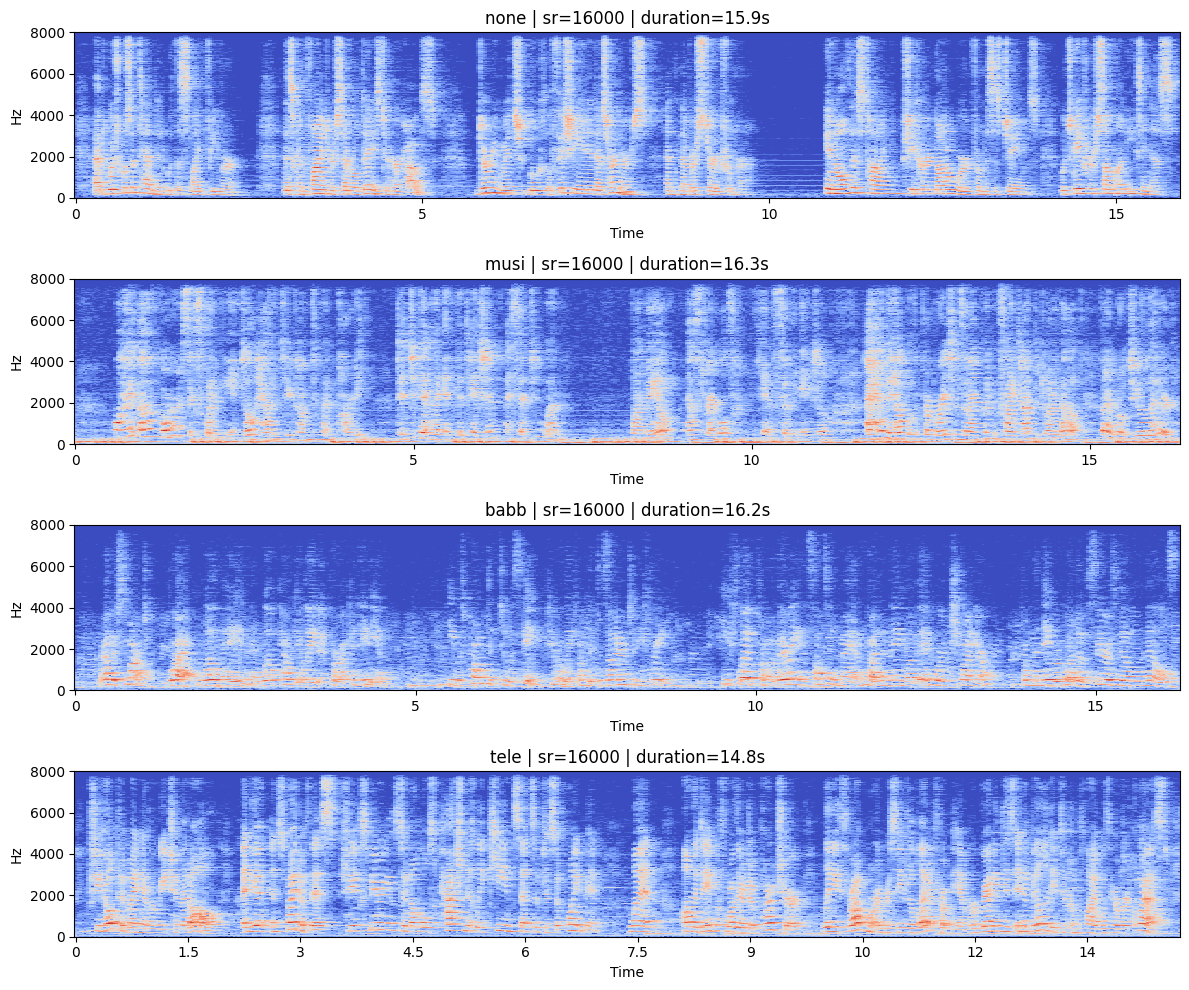

In [11]:
import librosa, librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, display

fig, axes = plt.subplots(4, 1, figsize=(12, 10))
for ax, noise in zip(axes, ["none", "musi", "babb", "tele"]):
    path = df[df["noise"] == noise]["path"].iloc[0]
    y, sr = librosa.load(path, sr=None)
    S = librosa.amplitude_to_db(abs(librosa.stft(y)))
    librosa.display.specshow(S, sr=sr, x_axis="time", y_axis="hz", ax=ax)
    ax.set_title(f"{noise} | sr={sr} | duration={len(y)/sr:.1f}s")
    display(Audio(y, rate=sr))
plt.tight_layout(); plt.show()

*Figure 1: Spectrograms of the four noise types (none, musi, babb, tele).*

## 3. Train and Test Split
The same sentence was recorded by several microphones, so splitting the data randomly would let the model see almost the same recording in both training and testing. To avoid this data leakage, I split the data by speaker using GroupShuffleSplit. About 75 percent of the speakers were used for training and 25 percent for testing, and no speaker appears in both sets. This gave 666 training files and 242 test files.

## 4. Task 1: Acoustic Event Detection
For each recording I extracted 20 MFCC coefficients, the spectral centroid, the zero crossing rate and the RMS energy. For every feature I computed the mean and the standard deviation over time, which gives a vector of 46 values for each file. The features were standardized before training.

In [12]:
import numpy as np
from tqdm import tqdm

def extract_features(path):
    y, sr = librosa.load(path, sr=16000)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
    zcr = librosa.feature.zero_crossing_rate(y)
    rms = librosa.feature.rms(y=y)
    feats = np.vstack([mfcc, centroid, zcr, rms])
    return np.concatenate([feats.mean(axis=1), feats.std(axis=1)])

X = np.array([extract_features(p) for p in tqdm(df["path"])])
y_labels = df["noise"].values
print(X.shape)

100%|██████████| 908/908 [01:06<00:00, 13.59it/s]

(908, 46)


In [13]:
from sklearn.model_selection import GroupShuffleSplit

df["speaker"] = df["fileName"].str.split("-").str[5]
groups = df["speaker"].values
print("Number of speakers:", len(np.unique(groups)))

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(gss.split(X, y_labels, groups))

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y_labels[train_idx], y_labels[test_idx]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Shared speakers:", set(groups[train_idx]) & set(groups[test_idx]))

Number of speakers: 104
Train: (666, 46) | Test: (242, 46)
Shared speakers: set()


I trained six classifiers: Logistic Regression, SVM, KNN, Decision Tree, Random Forest and a Multi Layer Perceptron (MLP). The results on the test set were as follows. MLP achieved the best accuracy of 73.1 percent, followed by SVM with 71.1 percent and Logistic Regression with 69.8 percent. Random Forest reached 63.6 percent, KNN 55.8 percent, and Decision Tree was the weakest with 45.0 percent. Since there are four classes, random guessing would give only 25 percent, so the results show that the models learned useful patterns.

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "SVM": SVC(C=10),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "MLP": MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=2000, random_state=42),
}

results = {}
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results[name] = pipe
    print(f"{name:20s} acc={accuracy_score(y_test, pred):.3f}  "
          f"F1={f1_score(y_test, pred, average='macro'):.3f}")

Logistic Regression  acc=0.698  F1=0.696
SVM                  acc=0.711  F1=0.701
KNN                  acc=0.558  F1=0.534
Decision Tree        acc=0.450  F1=0.438
Random Forest        acc=0.636  F1=0.619
MLP                  acc=0.731  F1=0.724


*Figure 2: Event detection results for the six classifiers.*

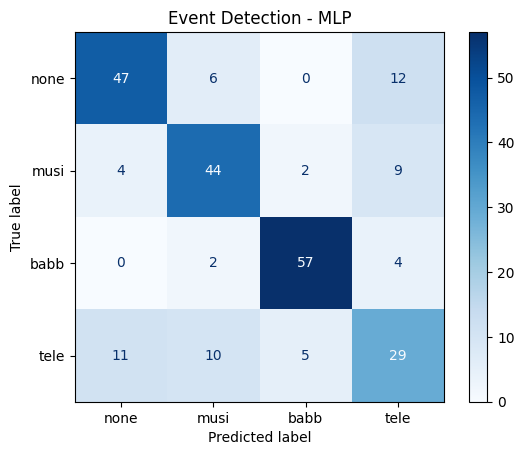

              precision    recall  f1-score   support

        none       0.76      0.72      0.74        65
        musi       0.71      0.75      0.73        59
        babb       0.89      0.90      0.90        63
        tele       0.54      0.53      0.53        55

    accuracy                           0.73       242
   macro avg       0.72      0.73      0.72       242
weighted avg       0.73      0.73      0.73       242



In [15]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best = results["MLP"]
pred = best.predict(X_test)
labels = ["none", "musi", "babb", "tele"]

ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=labels, cmap="Blues")
plt.title("Event Detection - MLP")
plt.show()

print(classification_report(y_test, pred, labels=labels))

The confusion matrix of the MLP showed that babble was the easiest class, with an F1 score of 0.90, because the sound of many people talking creates a constant noise across all frequencies. Television was the hardest class, with an F1 score of 0.53. It was often confused with the none class and with the music class. This makes sense, because television audio itself contains both speech and music.

*Figure 3: Confusion matrix and classification report of the MLP.*

## Part 2: Voice Activity Detection (VAD)

## 5. Task 2: Voice Activity Detection
### 5.1 Creating the labels
The VOiCES dataset does not provide labels for speech and silence at the frame level, so I had to create them. I divided each recording into frames of 32 milliseconds with a step of 16 milliseconds and computed the energy of each frame in decibels. For the clean recordings (none), a frame was labeled as speech if its energy was above a threshold placed halfway between the 10th and the 90th percentile of the energy in that file. A median filter was then applied to remove very short jumps in the labels.

In [16]:
parts = df["fileName"].str.split("-")
df["utt_id"] = parts.str[3] + "-" + parts.str[5] + "-" + parts.str[6] + "-" + parts.str[7] + "-" + parts.str[8]

counts = df.groupby("utt_id")["noise"].apply(lambda s: sorted(s.unique()))
print("Unique utterances:", len(counts))
print(counts.apply(len).value_counts())
print(counts.head(10))

Unique utterances: 685
noise
1    462
2    223
Name: count, dtype: int64
utt_id
rm1-sp0083-ch003054-sg0005-mc01          [musi]
rm1-sp0083-ch003054-sg0005-mc03          [babb]
rm1-sp0083-ch003054-sg0005-mc05          [none]
rm1-sp0083-ch003054-sg0005-mc07          [musi]
rm1-sp0093-ch126208-sg0004-mc01    [musi, tele]
rm1-sp0093-ch126208-sg0004-mc03          [babb]
rm1-sp0093-ch126208-sg0004-mc05          [babb]
rm1-sp0093-ch126208-sg0004-mc07    [musi, tele]
rm1-sp0150-ch126107-sg0026-mc01    [musi, tele]
rm1-sp0150-ch126107-sg0026-mc03          [none]
Name: noise, dtype: object


In [17]:
df["sent_id"] = parts.str[3] + "-" + parts.str[5] + "-" + parts.str[6] + "-" + parts.str[7]

has_none = df.groupby("sent_id")["noise"].apply(lambda s: "none" in s.values)
df["has_none"] = df["sent_id"].map(has_none)

noisy = df[df["noise"] != "none"]
print("Noisy files:", len(noisy))
print("Noisy files that have a 'none' version:", noisy["has_none"].sum())

Noisy files: 681
Noisy files that have a 'none' version: 510


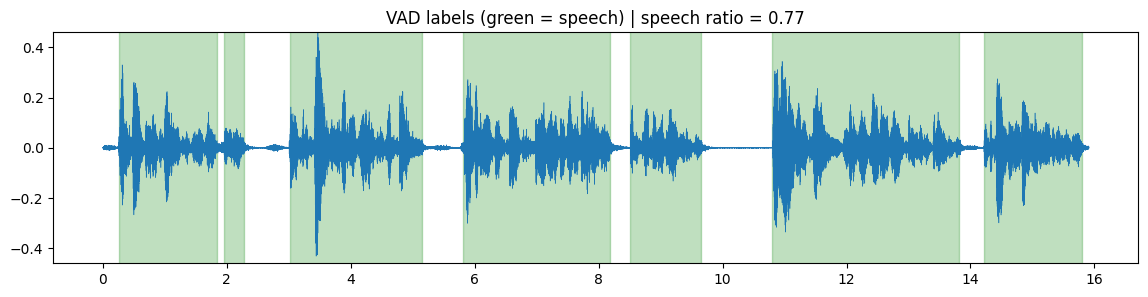

In [18]:
from scipy.ndimage import median_filter

SR, N_FFT, HOP = 16000, 512, 256   # each frame = 32ms, hop = 16ms

def energy_db(y):
    rms = librosa.feature.rms(y=y, frame_length=N_FFT, hop_length=HOP)[0]
    return librosa.amplitude_to_db(rms, ref=np.max)

def vad_labels(y):
    db = energy_db(y)
    thr = (np.percentile(db, 10) + np.percentile(db, 90)) / 2
    lab = (db > thr).astype(int)
    return median_filter(lab, size=11)

# test on one clean file
path = df[df["noise"] == "none"]["path"].iloc[0]
y, _ = librosa.load(path, sr=SR)
lab = vad_labels(y)
t = librosa.frames_to_time(np.arange(len(lab)), sr=SR, hop_length=HOP)

plt.figure(figsize=(14, 3))
plt.plot(np.arange(len(y))/SR, y, lw=0.4)
plt.fill_between(t, -1, 1, where=lab==1, color="green", alpha=0.25)
plt.ylim(-np.abs(y).max(), np.abs(y).max())
plt.title(f"VAD labels (green = speech) | speech ratio = {lab.mean():.2f}")
plt.show()

*Figure 4: Energy-based VAD labels on a clean recording.*

For the noisy recordings, energy alone cannot be used because the noise also has high energy. However, the same sentence was often recorded once without noise and once with noise. I matched each noisy file with its clean version, and then used cross-correlation to find the time shift between the two recordings. After correcting this shift, I copied the labels from the clean file to the noisy file. Out of 681 noisy files, 510 had a clean version and were used. In total, 737 files and about 718,000 frames were used for the VAD task.

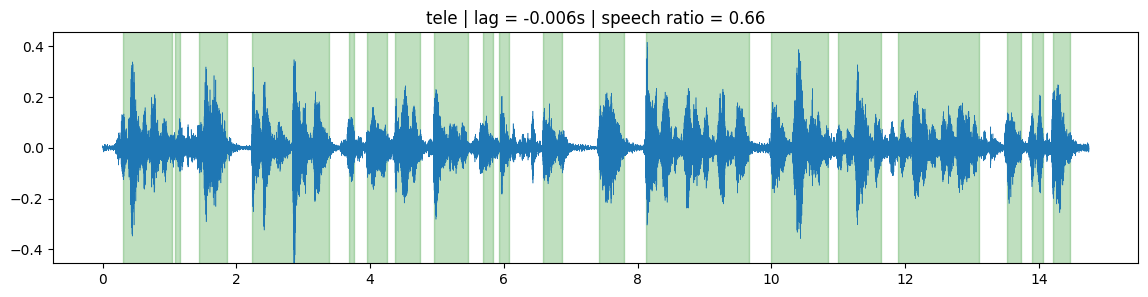

In [19]:
from scipy.signal import correlate

clean_of = df[df["noise"] == "none"].groupby("sent_id")["path"].first()

def aligned_labels(noisy_path, clean_path):
    yn, _ = librosa.load(noisy_path, sr=SR)
    yc, _ = librosa.load(clean_path, sr=SR)
    lab_c = vad_labels(yc)

    corr = correlate(yn, yc, mode="full", method="fft")
    lag = np.argmax(np.abs(corr)) - (len(yc) - 1)
    lag_f = int(round(lag / HOP))

    n_frames = 1 + len(yn) // HOP
    lab_n = np.zeros(n_frames, dtype=int)
    for i in range(n_frames):
        j = i - lag_f
        if 0 <= j < len(lab_c):
            lab_n[i] = lab_c[j]
    return yn, lab_n, lag / SR

# test on one noisy file
row = noisy[noisy["has_none"]].iloc[0]
yn, lab_n, lag_s = aligned_labels(row["path"], clean_of[row["sent_id"]])
t = librosa.frames_to_time(np.arange(len(lab_n)), sr=SR, hop_length=HOP)

plt.figure(figsize=(14, 3))
plt.plot(np.arange(len(yn))/SR, yn, lw=0.4)
plt.fill_between(t, -1, 1, where=lab_n==1, color="green", alpha=0.25)
plt.ylim(-np.abs(yn).max(), np.abs(yn).max())
plt.title(f"{row['noise']} | lag = {lag_s:.3f}s | speech ratio = {lab_n.mean():.2f}")
plt.show()

*Figure 5: Labels transferred to a noisy (TV) recording after alignment.*

### 5.2 Features and training
For each frame I extracted 13 MFCC coefficients, their first and second derivatives (delta and delta delta), the energy in decibels and the zero crossing rate, which gives 41 features per frame. I kept the same speaker split as in the first task. About 69 percent of the frames contain speech, which means that a model that always predicts speech would already reach 69 percent accuracy. For this reason, I also used balanced accuracy and the F1 score, and I set the class weights to balanced during training. Because the number of frames is very large, I trained the models on a random sample of 60,000 frames, and the SVM on 15,000 frames because it is slower.

In [20]:
def frame_features(y):
    mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=13, n_fft=N_FFT, hop_length=HOP)
    d1 = librosa.feature.delta(mfcc)
    d2 = librosa.feature.delta(mfcc, order=2)
    db = energy_db(y)[np.newaxis, :]
    zcr = librosa.feature.zero_crossing_rate(y, frame_length=N_FFT, hop_length=HOP)
    return np.vstack([mfcc, d1, d2, db, zcr]).T      # (n_frames, 41)

frames = []   # one entry per file
for _, row in tqdm(df.iterrows(), total=len(df)):
    if row["noise"] == "none":
        y, _ = librosa.load(row["path"], sr=SR)
        lab = vad_labels(y)
    elif row["has_none"]:
        y, lab, _ = aligned_labels(row["path"], clean_of[row["sent_id"]])
    else:
        continue                                      # no clean twin -> skip
    F = frame_features(y)
    n = min(len(F), len(lab))
    frames.append({"X": F[:n], "y": lab[:n], "noise": row["noise"], "speaker": row["speaker"]})

print("Files used:", len(frames))
print("Total frames:", sum(len(f["y"]) for f in frames))

100%|██████████| 908/908 [00:51<00:00, 17.53it/s]

Files used: 737
Total frames: 718353


In [21]:
train_spk = set(groups[train_idx])

def stack(fr_list):
    X = np.vstack([f["X"] for f in fr_list])
    y = np.concatenate([f["y"] for f in fr_list])
    nz = np.concatenate([[f["noise"]] * len(f["y"]) for f in fr_list])
    return X, y, nz

Xtr_v, ytr_v, _       = stack([f for f in frames if f["speaker"] in train_spk])
Xte_v, yte_v, nte_v   = stack([f for f in frames if f["speaker"] not in train_spk])
print("Train frames:", Xtr_v.shape, "| Test frames:", Xte_v.shape)
print("Speech ratio train/test:", ytr_v.mean().round(2), yte_v.mean().round(2))

# random sample of training frames (for speed)
rng = np.random.default_rng(42)
idx = rng.choice(len(ytr_v), 60000, replace=False)
Xs, ys = Xtr_v[idx], ytr_v[idx]

Train frames: (517445, 41) | Test frames: (200908, 41)
Speech ratio train/test: 0.69 0.69


In [22]:
from sklearn.metrics import balanced_accuracy_score

vad_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=16, class_weight="balanced",
                                            n_jobs=-1, random_state=42),
    "MLP": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True, random_state=42),
    "SVM (15k)": SVC(C=1, class_weight="balanced"),
}

vad_preds, rows = {}, []
for name, m in vad_models.items():
    pipe = make_pipeline(StandardScaler(), m)
    if "SVM" in name:
        pipe.fit(Xs[:15000], ys[:15000])          # SVM is slow -> smaller sample
    else:
        pipe.fit(Xs, ys)
    p = pipe.predict(Xte_v)
    vad_preds[name] = p
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(yte_v, p),
                 "Balanced Acc": balanced_accuracy_score(yte_v, p),
                 "F1 (speech)": f1_score(yte_v, p)})
    print(f"{name:20s} done")

vad_df = pd.DataFrame(rows).sort_values("Balanced Acc", ascending=False)
vad_df.round(3)

Logistic Regression  done
Decision Tree        done
Random Forest        done
MLP                  done
SVM (15k)            done


,Model,Accuracy,Balanced Acc,F1 (speech)
4,SVM (15k),0.904,0.898,0.929
0,Logistic Regression,0.896,0.894,0.923
2,Random Forest,0.910,0.891,0.935
3,MLP,0.909,0.891,0.935
1,Decision Tree,0.871,0.870,0.904


### 5.3 Results
All models performed much better than the 69 percent baseline. The SVM achieved the best balanced accuracy of 0.898, with an accuracy of 0.904. Logistic Regression reached a balanced accuracy of 0.894, Random Forest and MLP both reached 0.891 with the highest accuracy of about 0.91, and the Decision Tree reached 0.870. The fact that even Logistic Regression performed well shows that the chosen features, especially the energy and the MFCC derivatives, are very informative for detecting speech.

*Figure 6: VAD results for all classifiers.*

,none,musi,babb,tele
Model,,,,
Logistic Regression,0.909,0.895,0.887,0.881
Decision Tree,0.890,0.862,0.863,0.856
Random Forest,0.914,0.887,0.883,0.871
MLP,0.915,0.889,0.879,0.871
SVM (15k),0.915,0.896,0.889,0.884


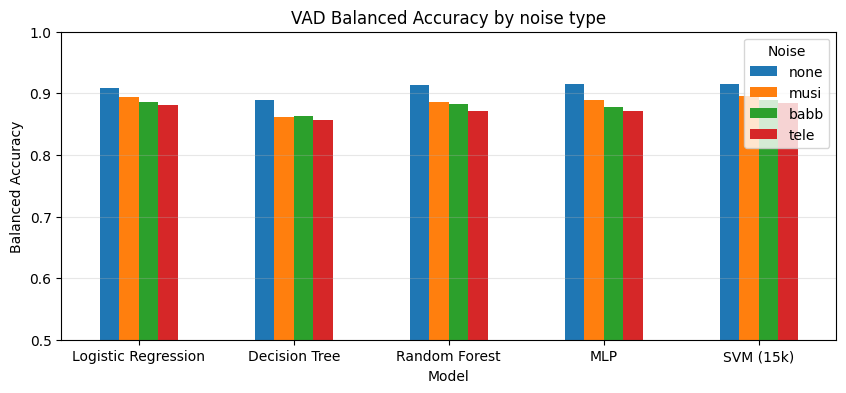

In [23]:
noise_rows = []
for name, p in vad_preds.items():
    r = {"Model": name}
    for nz in ["none", "musi", "babb", "tele"]:
        mask = nte_v == nz
        r[nz] = balanced_accuracy_score(yte_v[mask], p[mask])
    noise_rows.append(r)

noise_df = pd.DataFrame(noise_rows).set_index("Model")
display(noise_df.round(3))

noise_df.plot(kind="bar", figsize=(10, 4), ylim=(0.5, 1))
plt.title("VAD Balanced Accuracy by noise type")
plt.ylabel("Balanced Accuracy"); plt.xticks(rotation=0)
plt.legend(title="Noise"); plt.grid(axis="y", alpha=0.3)
plt.show()

When the results were separated by noise type, almost all models showed the same order (only the Decision Tree had music and babble almost equal). VAD was easiest for the recordings without noise (balanced accuracy of 0.915 with SVM), followed by music (0.896), babble (0.889), and television (0.884), which was the hardest. Television is difficult because it contains other people speaking, and the model has to separate this speech from the speech of the main speaker.

*Figure 7: VAD balanced accuracy by noise type.*

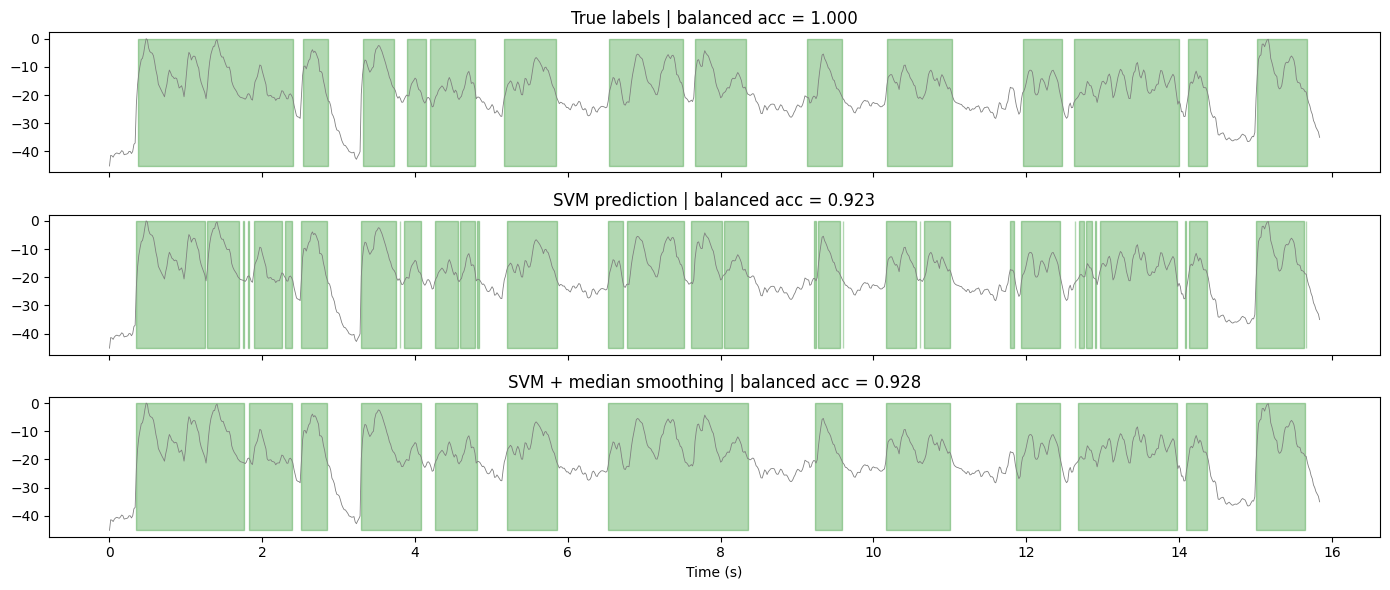

In [24]:
test_frames = [f for f in frames if f["speaker"] not in train_spk]
starts = np.cumsum([0] + [len(f["y"]) for f in test_frames])

k = next(i for i, f in enumerate(test_frames) if f["noise"] == "tele")
s, e = starts[k], starts[k + 1]

y_true = yte_v[s:e]
y_pred = vad_preds["SVM (15k)"][s:e]
y_smooth = median_filter(y_pred, size=11)
energy = Xte_v[s:e, 39]                       # column 39 = energy in dB
t = np.arange(e - s) * HOP / SR

fig, ax = plt.subplots(3, 1, figsize=(14, 6), sharex=True)
for a, lab, title in zip(ax, [y_true, y_pred, y_smooth],
                         ["True labels", "SVM prediction", "SVM + median smoothing"]):
    a.plot(t, energy, color="gray", lw=0.6)
    a.fill_between(t, energy.min(), energy.max(), where=lab == 1, color="green", alpha=0.3)
    a.set_title(f"{title} | balanced acc = {balanced_accuracy_score(y_true, lab):.3f}")
ax[-1].set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

Finally, I plotted the predictions of the SVM on a test recording with television noise. The raw predictions contained some isolated frames that switched between speech and silence. After applying a median filter to the predictions, the speech segments became smoother and the balanced accuracy on this file improved from 0.923 to 0.928. However, the filter also merged a few short pauses, so there is a trade-off when choosing the filter size.

*Figure 8: True labels, SVM prediction and smoothed prediction on a TV noise recording.*

## 6. Conclusion
In this assignment, both event detection and voice activity detection were performed on the VOiCES dataset. For event detection, the MLP gave the best result with 73 percent accuracy, and television noise was the hardest to recognize. For voice activity detection, the SVM gave the best balanced accuracy of 0.898, and the performance decreased as the background noise became more similar to speech. Splitting the data by speaker and aligning the clean and noisy recordings were important steps to get reliable labels and a fair evaluation.

## 7. Limitations
The labels for the clean recordings were created from the energy of the same files, so the VAD results for the none class may be slightly optimistic. In addition, 171 noisy files did not have a clean version and could not be used in the VAD task.